# Which months, states and categories go with unhappy customers?

Phase 3, Step 7. Trends and breakdowns with pandas and charts, read from the **analytics** tables
that `python -m src.pipeline` builds in PostgreSQL. "Unhappy" = a 1-2 star review; every rate says
what it is out of.

**Contents:** 1. Setup · 2. Monthly trends · 3. Delivery by customer state · 4. Unhappy rate by
category (on-time orders) · 5. Odd values · 6. What we see · 7. Limitations

**Summary (all numbers come from the outputs below):**
- Months with fewer on-time deliveries had more unhappy customers: March 2018 had the lowest on-time rate (81.04%) and the highest unhappy rate (22.80%).
- States with more late deliveries tend to have higher unhappy rates: MA 17.43% late and 19.94% unhappy, against SP 4.49% and 10.71%.
- Even on on-time orders, office furniture is linked with about twice the usual unhappy rate (17.15% vs 8.48%).

## 1. Setup
Connect with the project's own helper (`src/db.py` reads the password from `.env`, never printed),
and set one quiet chart style used by every chart.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import text

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))            # so "from src..." works when run from notebooks/
from src.db import get_engine

engine = get_engine()

def query(sql: str) -> pd.DataFrame:
    """Run one SQL query and return the result as a table."""
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn)

In [2]:
# One chart style: light surface, grey axes and grid, one blue for single-series charts
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, BLUE = "#e1e0d9", "#c3c2b7", "#2a78d6"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,  # grid behind bars
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "figure.dpi": 110,
})

## 2. Monthly trends (main period, Jan 2017 - Aug 2018)
Three panels share the month axis instead of one chart with two y-scales.
Orders count every order; on-time rate is out of delivered orders with both dates; unhappy rate is
out of reviewed orders. The months come from `dim_date` (the star schema's date table).

In [3]:
monthly = query("""
    SELECT d.month_start,
           count(*) AS orders,
           round(100.0 * count(*) FILTER (WHERE f.order_status = 'delivered' AND NOT f.is_late)
                 / count(*) FILTER (WHERE f.order_status = 'delivered' AND f.days_late IS NOT NULL), 2) AS on_time_pct,
           round(100.0 * count(*) FILTER (WHERE f.is_unhappy) / count(*) FILTER (WHERE f.has_review), 2) AS unhappy_pct
    FROM analytics.fact_order f
    JOIN analytics.dim_date d ON d.date_day = f.purchase_date
    WHERE f.in_main_period
    GROUP BY d.month_start
    ORDER BY d.month_start
""")
monthly["month_start"] = pd.to_datetime(monthly["month_start"])
monthly

,month_start,orders,on_time_pct,unhappy_pct
0,2017-01-01,800,97.07,15.57
1,2017-02-01,1780,97.04,16.18
2,2017-03-01,2682,95.44,14.28
3,2017-04-01,2404,93.44,15.46
4,2017-05-01,3700,97.01,12.82
5,2017-06-01,3245,96.97,12.80
6,2017-07-01,4026,97.21,12.38
7,2017-08-01,4331,97.09,11.47
8,2017-09-01,4285,95.61,12.49
9,2017-10-01,4631,95.82,13.26


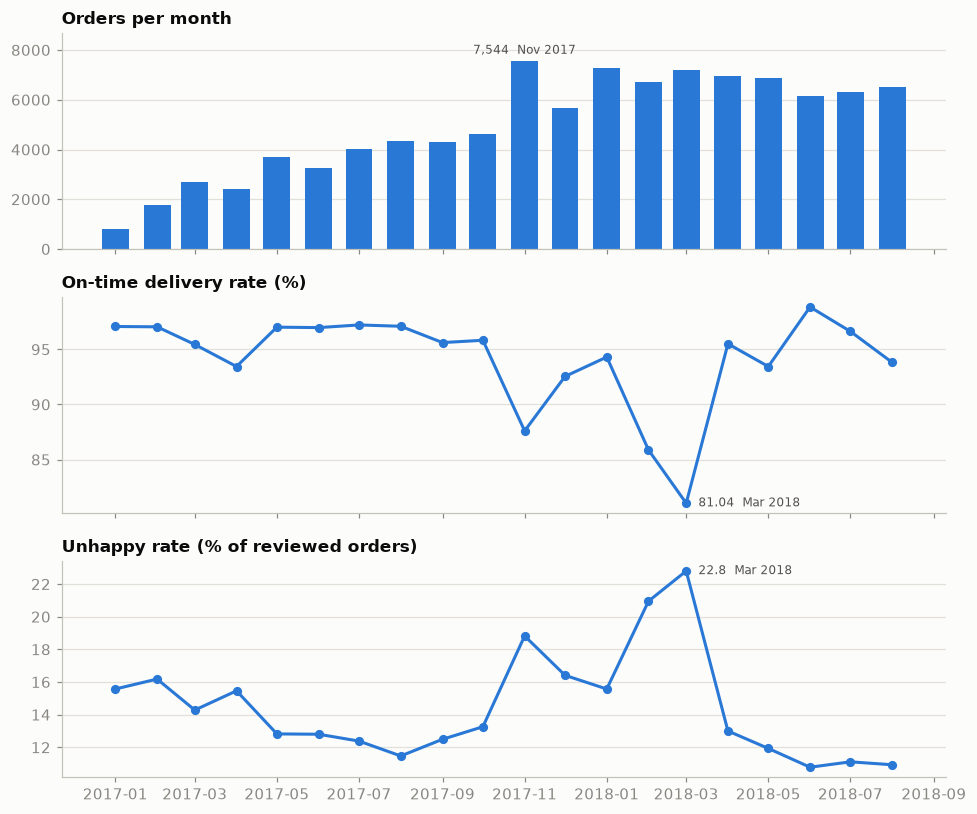

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(9, 7.5), sharex=True)
panels = [("orders", "Orders per month"), ("on_time_pct", "On-time delivery rate (%)"),
          ("unhappy_pct", "Unhappy rate (% of reviewed orders)")]
for ax, (col, title) in zip(axes, panels):
    if col == "orders":
        ax.bar(monthly["month_start"], monthly[col], width=20, color=BLUE)
    else:
        ax.plot(monthly["month_start"], monthly[col], color=BLUE, marker="o", markersize=5)
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
    # label only the extreme month, not every point
    i = monthly[col].idxmin() if col == "on_time_pct" else monthly[col].idxmax()
    label = f"{monthly.loc[i, col]:,g}  {monthly.loc[i, 'month_start']:%b %Y}"
    if col == "orders":   # above the bar, with headroom so it doesn't touch the frame
        ax.set_ylim(0, monthly[col].max() * 1.15)
        ax.annotate(label, (monthly.loc[i, "month_start"], monthly.loc[i, col]), textcoords="offset points",
                    xytext=(0, 3), ha="center", va="bottom", color=INK_2, fontsize=8)
    else:
        ax.annotate(label, (monthly.loc[i, "month_start"], monthly.loc[i, col]), textcoords="offset points",
                    xytext=(8, 0), va="center", color=INK_2, fontsize=8)
fig.tight_layout()
plt.show()

## 3. Delivery by customer state
Delivered orders with both dates, by the **customer's** state. States with fewer than 500 such orders
are left out of the chart (too few for a steady rate) but stay in the table. Two panels share the
same state order, so lateness and unhappiness can be read side by side.

In [5]:
states = query("""
    SELECT c.state,
           count(*) AS delivered_orders,
           percentile_cont(0.5) WITHIN GROUP (ORDER BY f.delivery_days) AS median_delivery_days,
           round(100.0 * count(*) FILTER (WHERE f.is_late) / count(*), 2) AS late_pct,
           count(*) FILTER (WHERE f.has_review) AS reviewed,
           round(100.0 * count(*) FILTER (WHERE f.is_unhappy) / count(*) FILTER (WHERE f.has_review), 2) AS unhappy_pct
    FROM analytics.fact_order f
    JOIN analytics.dim_customer c ON c.customer_id = f.customer_id
    WHERE f.order_status = 'delivered' AND f.days_late IS NOT NULL
    GROUP BY c.state
    ORDER BY late_pct DESC
""")
states

,state,delivered_orders,median_delivery_days,late_pct,reviewed,unhappy_pct
0,AL,397,22.0,21.41,394,21.32
1,MA,717,19.0,17.43,712,19.94
2,SE,335,18.0,15.22,334,18.86
3,PI,476,16.0,13.87,471,16.14
4,CE,1279,18.0,13.76,1273,17.28
5,RR,41,25.0,12.20,41,14.63
6,BA,3256,17.0,12.16,3229,17.06
7,RJ,12350,12.0,12.11,12211,18.39
8,PA,946,21.0,11.21,933,18.11
9,ES,1995,14.0,10.73,1969,13.81


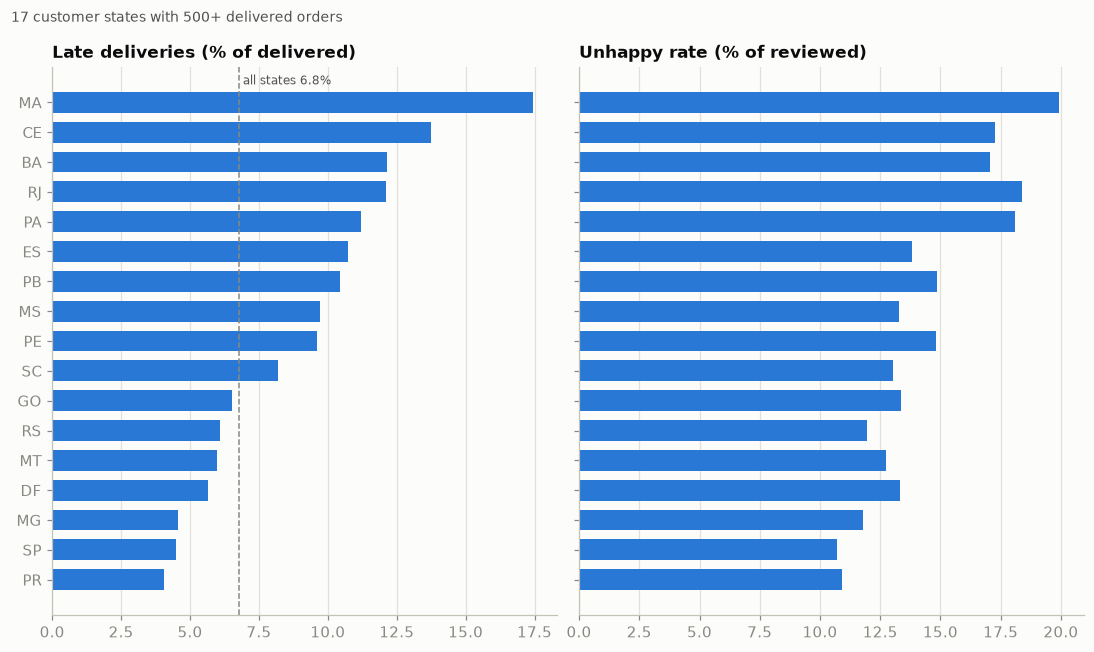

In [6]:
big = states[states["delivered_orders"] >= 500].sort_values("late_pct")
overall_late = query("""SELECT 100.0 * count(*) FILTER (WHERE is_late) / count(*) AS pct
                         FROM analytics.fact_order
                         WHERE order_status = 'delivered' AND days_late IS NOT NULL""")["pct"][0]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6), sharey=True)
ax1.barh(big["state"], big["late_pct"], color=BLUE, height=0.7)
ax1.axvline(overall_late, color=MUTED, linestyle="--", linewidth=1)
ax1.text(overall_late, len(big) - 0.4, f" all states {overall_late:.1f}%", color=INK_2, fontsize=8)
ax1.set_title("Late deliveries (% of delivered)")
ax2.barh(big["state"], big["unhappy_pct"], color=BLUE, height=0.7)
ax2.set_title("Unhappy rate (% of reviewed)")
for ax in (ax1, ax2):
    ax.grid(axis="y", visible=False)
fig.suptitle(f"{len(big)} customer states with 500+ delivered orders", x=0.01, ha="left", color=INK_2, fontsize=9)
fig.tight_layout()
plt.show()

## 4. Unhappy rate by category, on-time orders only
Same rules as P3 (`sql/questions/03_p3_product_value.sql`): single-product orders, delivered on
time, categories with 500+ such reviewed orders. Looking only at on-time orders keeps lateness out
of the comparison.

In [7]:
categories = query("""
    WITH single AS (
      SELECT order_id, min(product_id) AS product_id FROM analytics.fact_order_item
      GROUP BY order_id HAVING count(DISTINCT product_id) = 1
    )
    SELECT p.product_category,
           count(*) AS reviewed_on_time,
           count(*) FILTER (WHERE f.is_unhappy) AS unhappy_on_time,
           round(100.0 * count(*) FILTER (WHERE f.is_unhappy) / count(*), 2) AS unhappy_on_time_pct
    FROM single s
    JOIN analytics.fact_order f  ON f.order_id = s.order_id
    JOIN analytics.dim_product p ON p.product_id = s.product_id
    WHERE f.has_review AND f.order_status = 'delivered' AND f.days_late <= 0
    GROUP BY p.product_category
    ORDER BY unhappy_on_time_pct DESC
""")
ranked = categories[categories["reviewed_on_time"] >= 500].sort_values("unhappy_on_time_pct")
# reference = all on-time single-product orders, every category (exact counts, not rounded rates)
reference = 100 * categories["unhappy_on_time"].sum() / categories["reviewed_on_time"].sum()
print(f"{len(ranked)} categories ranked; reference on-time unhappy rate {reference:.2f}%")
ranked.sort_values("unhappy_on_time_pct", ascending=False)

26 categories ranked; reference on-time unhappy rate 8.48%


,product_category,reviewed_on_time,unhappy_on_time,unhappy_on_time_pct
3,office_furniture,1102,189,17.15
13,unknown,1223,146,11.94
17,computers_accessories,5879,619,10.53
18,telephony,3683,376,10.21
19,furniture_decor,5399,550,10.19
20,bed_bath_table,7766,791,10.19
25,small_appliances,568,52,9.15
27,watches_gifts,4874,438,8.99
29,electronics,2273,201,8.84
30,home_appliances,711,62,8.72


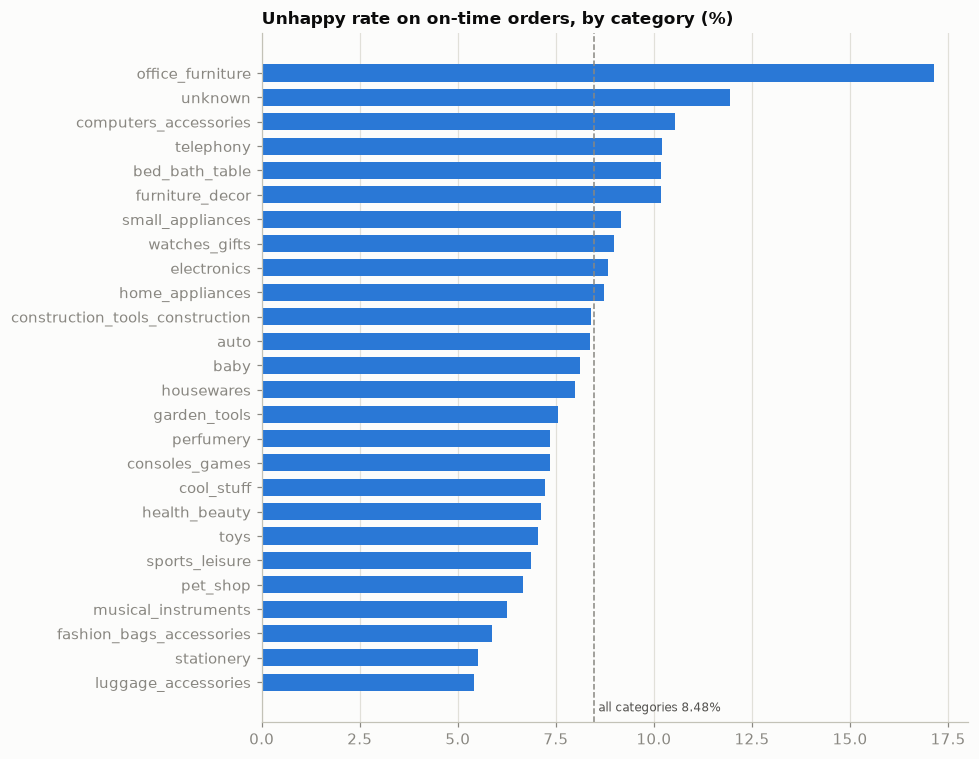

In [8]:
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(ranked["product_category"], ranked["unhappy_on_time_pct"], color=BLUE, height=0.7)
ax.axvline(reference, color=MUTED, linestyle="--", linewidth=1)
ax.text(reference, -1.2, f" all categories {reference:.2f}%", color=INK_2, fontsize=8)
ax.set_title("Unhappy rate on on-time orders, by category (%)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

## 5. Odd values
How long deliveries take (delivered orders with both dates), with the extreme tail counted rather
than hidden, plus how many rows carry each Phase 2 flag.

In [9]:
days = query("""SELECT delivery_days FROM analytics.fact_order
                 WHERE order_status = 'delivered' AND days_late IS NOT NULL""")["delivery_days"]
print(days.describe().round(1).to_string())
print(f"orders over 60 days: {(days > 60).sum():,} of {len(days):,}")

count    96470.0
mean        12.5
std          9.6
min          0.0
25%          7.0
50%         10.0
75%         16.0
max        210.0
orders over 60 days: 298 of 96,470


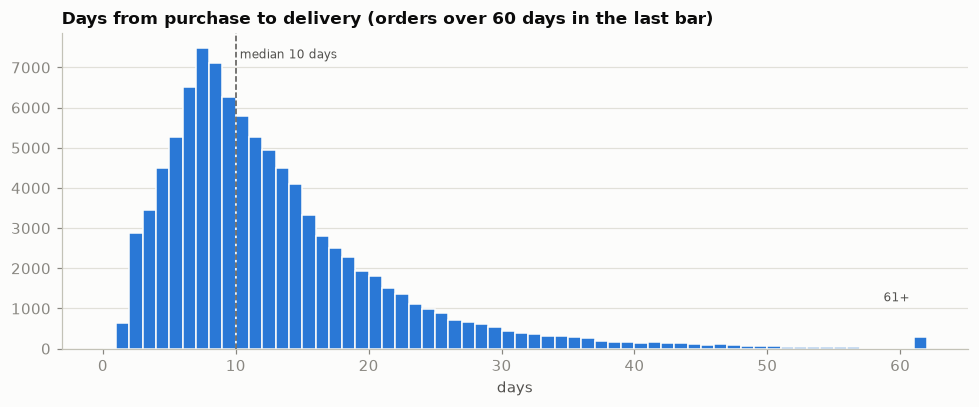

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(days.clip(upper=61), bins=range(0, 63), color=BLUE, edgecolor=SURFACE, linewidth=1)
ax.axvline(days.median(), color=INK_2, linestyle="--", linewidth=1)
ax.text(days.median(), ax.get_ylim()[1] * 0.92, f" median {days.median():g} days", color=INK_2, fontsize=8)
ax.text(61, ax.get_ylim()[1] * 0.15, "61+ ", ha="right", color=INK_2, fontsize=8)
ax.set_title("Days from purchase to delivery (orders over 60 days in the last bar)")
ax.set_xlabel("days")
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

In [11]:
flags = query("""
    SELECT count(*) FILTER (WHERE flag_delivered_without_date)      AS delivered_without_date,
           count(*) FILTER (WHERE flag_delivery_date_not_delivered) AS delivery_date_not_delivered,
           count(*) FILTER (WHERE flag_handover_before_purchase)    AS handover_before_purchase,
           count(*) FILTER (WHERE flag_delivered_before_handover)   AS delivered_before_handover,
           count(*) FILTER (WHERE flag_odd_deadline)                AS odd_deadline,
           count(*) FILTER (WHERE flag_paid_mismatch)               AS paid_mismatch
    FROM analytics.fact_order
""")
flags.T.rename(columns={0: "orders"})

,orders
delivered_without_date,8
delivery_date_not_delivered,6
handover_before_purchase,166
delivered_before_handover,23
odd_deadline,10
paid_mismatch,249


## 6. What we see
These are patterns: things that go together, not proof that one causes the other.

- **Monthly trends:** the on-time rate stays around 93-99% in most months, but it falls in November
  2017 (87.60%, the busiest month with 7,544 orders) and in February-March 2018 (85.87%, 81.04%).
  The unhappy rate rises in the same months (18.82%, 20.95%, 22.80%), then drops back to about 11%
  from May 2018.
- **States:** among the 17 customer states with 500+ delivered orders, MA (17.43%), CE (13.76%),
  BA (12.16%) and RJ (12.11%) are late most often, and their unhappy rates (17.06-19.94%) are among
  the highest. SP, the largest state (40,494 delivered orders), has the shortest median delivery
  (7 days), 4.49% late and 10.71% unhappy. AL has the highest late rate of all (21.41%) but only
  397 delivered orders, so it is in the table, not the chart.
- **Categories (on time only):** 26 categories qualify. Office furniture (17.15%) and products with
  no category (11.94%) are well above the 8.48% reference; luggage (5.41%) and stationery (5.51%)
  are lowest.
- **Odd values:** half of the delivered orders arrive within 10 days and three quarters within 16;
  the average (12.5 days) is pulled up by a long tail: 298 of 96,470 orders took over 60 days, the
  longest 210. This is why the project uses medians for waiting times. The flag counts match the
  Phase 2 data quality report.

## 7. Limitations
1. **Patterns, not causes.** Months and states differ in many ways at once (order volume, distance
   from sellers, product mix). Phase 4 compares like with like and checks the gaps against chance.
2. **Purchase month, not review month.** Monthly rates group orders by when they were bought.
3. **Some ratings came before the parcel.** Many late orders were rated before they arrived
   (see the P1 check in `sql/questions/01_p1_delivery_promise.sql`), which raises unhappy rates in
   late months and states.
4. **Small states left out of the chart.** States under 500 delivered orders appear only in the
   table, because their rates move a lot with a few orders.
5. **Category view uses single-product, on-time, reviewed orders only**, so each review maps to one
   category and lateness is kept out.
6. **Multi-seller orders:** one recorded delivery date may not cover every parcel (see P2).